# Potato Leaf Disease Classification — ResNet-50 (M3CA+DLR+APA), EOS-Balanced

Architecture: full ResNet-50 backbone + M3CA + DLR + APA, EOS-balanced training.


## 1. Setup, Imports, Config (All Hyperparameters Here for Manual Tuning)

In [1]:
import os, glob, random, math
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, PercentFormatter
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
try:
    from torch.amp import autocast as _autocast_new
    def autocast(device_type, enabled=True):
        return _autocast_new(device_type=device_type, enabled=enabled)
except ImportError:
    from torch.cuda.amp import autocast as _autocast_old
    def autocast(device_type, enabled=True):
        return _autocast_old(enabled=enabled)
from torch.amp import GradScaler
from torchvision import transforms, models
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.neighbors import NearestNeighbors
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

CLASSES = ["Bacteria", "Fungi", "Healthy", "Nematode", "Pest", "Phytophthora", "Virus"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)

IMG_SIZE = 512
BATCH_SIZE = 8
ACCUM_STEPS = 4
NUM_EPOCHS = 70  # fixed final run length, no early stopping

DROP_PATH_RATE = 0.10

# ---- M3CA block settings ----
# M3CA compresses the ResNet's 2048-ch output to M3CA_REDUCED channels for the
# morphological/multiscale processing, then projects back to 2048 (residual).
M3CA_REDUCED = 256
# Structuring-element size for the fixed morphology (white top-hat and
# morphological gradient). 3x3 initially; compare 5x5 experimentally.
M3CA_MORPH_K = 3
BILINEAR_REDUCED_DIM = 64
GEM_P_INIT = 3.0
DROPOUT_MAIN = 0.20   # main-head dropout -- raise if val loss still rises late
DROPOUT_AUX = 0.30    # aux-head dropout

# ---- Learning rates: three param groups (backbone, layer4, new custom blocks) ----
LR_BACKBONE = 3e-6
LR_LAYER4 = 1.2e-5
LR_NEW_BLOCKS = 1e-4
WEIGHT_DECAY_BACKBONE = 2e-4
WEIGHT_DECAY_NEW_BLOCKS = 5e-4
WARMUP_EPOCHS = 10

# ---- Cosine LR schedule ----
# ETA_MIN raised from 1e-7 -> 1e-5: in the 90.04-accuracy run, the cosine schedule
# decayed LR_NEW_BLOCKS to near-zero by epoch 50-60, which coincided exactly with
# val loss beginning to climb while val accuracy kept slowly rising -- the
# classifier lost the ability to correct itself on hard minority examples once
# LR bottomed out. Raising the floor keeps enough plasticity late in training.
ETA_MIN = 1e-5

# ---- Loss function ----
# LABEL_SMOOTHING and FOCAL_GAMMA both directly control how confidently the model
# is allowed to commit to a prediction -- the second and third levers to try if
# val loss still rises late despite the ETA_MIN change above.
LABEL_SMOOTHING = 0.15  # raised from 0.10
FOCAL_GAMMA = 2.0
CB_BETA = 0.999
AUX_LOSS_WEIGHT = 0.30
AUX_WARMUP_EPOCHS = 10
CONTRASTIVE_WEIGHT = 0.10
CONTRASTIVE_TEMPERATURE = 0.10

# ---- EOS: Expansive Over-Sampling, Dablain et al. 2022 ----
EOS_K_NEIGHBORS = 5      # reduced from the paper's K=10, given Nematode's 48 training samples
EOS_PHASE3_EPOCHS = 10   # exact value used in the paper's own embedding-space experiments

NUM_WORKERS = min(2, os.cpu_count() or 2)
CKPT_DIR = "/kaggle/working/checkpoints_resnet50_m3ca_dlr"  # separate dir: do not overwrite the 92.51% run's checkpoints
os.makedirs(CKPT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE} | GPUs: {torch.cuda.device_count() if DEVICE.type == 'cuda' else 0}")

Using device: cuda | GPUs: 2


## 2. Data Loading and 70/15/15 Split

In [2]:
import hashlib

def find_class_root(root):
    for dirpath, dirnames, filenames in os.walk(root):
        has_images_here = any(f.lower().endswith((".jpg", ".jpeg", ".png")) for f in filenames)
        if len(dirnames) >= 5 and not has_images_here:
            if any(any(f.lower().endswith((".jpg", ".jpeg", ".png")) for f in os.listdir(os.path.join(dirpath, d))) for d in dirnames):
                return dirpath
    return root

roots = glob.glob("/kaggle/input/datasets/nirmalsankalana/potato-leaf-disease-dataset")
if not roots:
    roots = glob.glob("/kaggle/input/*")
if not roots:
    raise FileNotFoundError("Attach the potato leaf disease dataset to this Kaggle notebook.")

DATA_ROOT = find_class_root(roots[0])
print(f"Resolved DATA_ROOT: {DATA_ROOT}")

records = []
for cls in CLASSES:
    cls_dir = os.path.join(DATA_ROOT, cls)
    if not os.path.isdir(cls_dir):
        alternatives = [d for d in os.listdir(DATA_ROOT) if d.lower().startswith(cls[:4].lower())]
        if not alternatives:
            raise FileNotFoundError(f"Could not find the folder for class: {cls}")
        cls_dir = os.path.join(DATA_ROOT, alternatives[0])
    for filename in os.listdir(cls_dir):
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            records.append({"path": os.path.join(cls_dir, filename), "label": CLASS_TO_IDX[cls]})

df = pd.DataFrame(records).sample(frac=1, random_state=SEED).reset_index(drop=True)

# ---- Deduplicate BEFORE splitting: compute a file-content hash for every image
# and drop exact duplicates, keeping only the first occurrence. This prevents the
# same physical photo from ending up in two different splits, which was confirmed
# to affect ~3.5% of val and ~1.1% of test images and was artificially inflating
# early-epoch validation performance. ----

def file_hash(filepath):
    with open(filepath, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

print("Hashing all images to detect duplicates...")
df["file_hash"] = df["path"].apply(file_hash)
duplicate_count = df["file_hash"].duplicated().sum()
print(f"Found {duplicate_count} duplicate images across the entire dataset ({duplicate_count / len(df) * 100:.1f}%)")
df = df.drop_duplicates(subset="file_hash", keep="first").drop(columns="file_hash").reset_index(drop=True)
print(f"Dataset size after deduplication: {len(df)}")

train_df, rest_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(rest_df, test_size=0.50, stratify=rest_df["label"], random_state=SEED)

print(f"Total: {len(df)}  Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")
for split_name, split_df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    counts = split_df["label"].value_counts().sort_index()
    print(f"  {split_name}: " + ", ".join(f"{CLASSES[i]}={counts.get(i, 0)}" for i in range(NUM_CLASSES)))

train_df.to_csv(f"{CKPT_DIR}/train_manifest.csv", index=False)
val_df.to_csv(f"{CKPT_DIR}/val_manifest.csv", index=False)
test_df.to_csv(f"{CKPT_DIR}/test_manifest.csv", index=False)

Resolved DATA_ROOT: /kaggle/input/datasets/nirmalsankalana/potato-leaf-disease-dataset
Hashing all images to detect duplicates...
Found 55 duplicate images across the entire dataset (1.8%)
Dataset size after deduplication: 3021
Total: 3021  Train: 2114  Val: 453  Test: 454
  Train: Bacteria=398, Fungi=519, Healthy=139, Nematode=47, Pest=423, Phytophthora=216, Virus=372
  Val: Bacteria=85, Fungi=111, Healthy=30, Nematode=10, Pest=90, Phytophthora=47, Virus=80
  Test: Bacteria=86, Fungi=112, Healthy=30, Nematode=10, Pest=91, Phytophthora=46, Virus=79


In [3]:
get_ipython().system("pip install -q imagehash")
import hashlib
from PIL import Image
import imagehash

def file_hash(filepath):
    with open(filepath, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def perceptual_hash(filepath):
    return str(imagehash.phash(Image.open(filepath).convert("RGB")))

train_hashes = [file_hash(p) for p in train_df["path"]]
val_hashes = [file_hash(p) for p in val_df["path"]]
test_hashes = [file_hash(p) for p in test_df["path"]]
print(f"Exact duplicates -- train/val: {len(set(train_hashes) & set(val_hashes))}, "
      f"train/test: {len(set(train_hashes) & set(test_hashes))}, "
      f"val/test: {len(set(val_hashes) & set(test_hashes))}")

train_phash = [perceptual_hash(p) for p in train_df["path"]]
val_phash = [perceptual_hash(p) for p in val_df["path"]]
test_phash = [perceptual_hash(p) for p in test_df["path"]]
print(f"Near-duplicates -- train/val: {len(set(train_phash) & set(val_phash))}, "
      f"train/test: {len(set(train_phash) & set(test_phash))}")

Exact duplicates -- train/val: 0, train/test: 0, val/test: 0
Near-duplicates -- train/val: 0, train/test: 0


## 3. Augmentation and Dataset (Online, Unchanged From the 90.04-Accuracy Run)

In [4]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.78, 1.0), ratio=(0.88, 1.12)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.15),
    transforms.RandomApply([transforms.RandomRotation(18)], p=0.5),
    transforms.RandomApply([transforms.ColorJitter(brightness=0.18, contrast=0.18, saturation=0.15, hue=0.03)], p=0.65),
    transforms.RandAugment(num_ops=2, magnitude=6),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.20, scale=(0.01, 0.08), ratio=(0.4, 2.5)),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class PotatoLeafDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image = Image.open(row["path"]).convert("RGB")
        return self.transform(image), int(row["label"])

train_ds = PotatoLeafDataset(train_df, train_transform)
val_ds = PotatoLeafDataset(val_df, eval_transform)
test_ds = PotatoLeafDataset(test_df, eval_transform)

class_counts = train_df["label"].value_counts().sort_index().values.astype(float)
sampling_weights = train_df["label"].map(lambda i: 1.0 / math.sqrt(class_counts[i])).values
sampler = WeightedRandomSampler(
    torch.as_tensor(sampling_weights, dtype=torch.double),
    num_samples=len(sampling_weights),
    replacement=True,
)

loader_kwargs = dict(num_workers=NUM_WORKERS, pin_memory=True)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, drop_last=True, **loader_kwargs)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
print(f"Train steps/epoch: {len(train_loader)}")

Train steps/epoch: 264


## 4. Architecture — Full ResNet-50 Backbone, then M3CA → DLR → APA

The complete ResNet-50 convolutional backbone (stem + layer1-4, retaining the
existing stochastic-depth regularization) runs first, with no custom blocks
interleaved between its stages. Its final 2048-channel feature map — taken
before ResNet's original global pooling and classifier — is refined
sequentially by the custom blocks: **M3CA → DLR → APA**. Both classification
heads (main + auxiliary) run on the APA-refined features.

### M3CA — Multiscale Morphological and Coordinate-Attention Block

**Motivation:** visually similar potato leaf diseases in uncontrolled
environments. Similar-looking classes can differ in lesion size, boundary
shape, and texture distribution — small sunken spots with yellow borders
(fungal early blight) vs water-soaked dark necrotic patches not restricted by
veins (Phytophthora late blight) vs diffuse deficiency-like yellowing
(nematode) vs mottling (virus) ([dataset paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC10733095/);
[MSU Extension](https://www.canr.msu.edu/resources/potato_diseases_early_blight_e2991);
[Ontario Crop IPM](https://cropipm.omafra.gov.on.ca/en-ca/crops/potatoes/diseases/804fa9d9-c964-4fc1-ab30-153137c3c6e1);
[UF IFAS](https://ask.ifas.ufl.edu/publication/NG029)).

**Pipeline (order is deliberate — first extract explicit morphological cues,
then learn how to interpret those cues across spatial scales, finally
recalibrate the combined representation):**

1. **Channel compression** — 1x1 conv, 2048 → 256 channels.
2. **Fixed mathematical morphology** (parameter-free, on the compressed maps):
   white top-hat \(T = X - (X \circ B)\) for bright, small-scale structures;
   morphological gradient \(G = \delta_B(X) - \varepsilon_B(X)\) for lesion
   boundaries and local transitions. Structuring element 3x3 initially
   (M3CA_MORPH_K config; compare 5x5 experimentally).
3. **Morphological fusion** — concat → 1x1 conv → 256 channels.
4. **Multiscale texture** — parallel depthwise-separable 3x3 (local patterns)
   and dilated 3x3, dilation 2 (broader lesion context).
5. **Selective-Kernel fusion** — input-dependent per-channel weights over the
   two receptive-field branches, so the network can favour finer or broader
   context depending on the input.
6. **Coordinate Attention** — direction-aware channel recalibration that keeps
   horizontal/vertical position information (elongated lesions, vein-associated
   patterns, distributed spots).
7. **Residual fusion** — project 256 → 2048 and combine with the original
   ResNet features: \(Y = F + \alpha\, P(Z)\), with learnable scalar
   \(\alpha\) initialised to 0.1, so the pretrained representation is
   preserved while the model gradually learns whether the additional features
   help.

**Honest caveats:** (a) this is a proposed research architecture, not a claim
of proven novelty or improved accuracy; (b) the morphology operates on latent
16x16 stride-32 feature maps — it exposes contrasts in learned activations and
cannot recover pixel-level detail already discarded by the backbone; (c) not
every potato disease has bright lesions or sharp boundaries, so the top-hat
branch is intended to complement learned features rather than determine
predictions by itself; (d) the small initial \(\alpha\) is a design choice,
not a guarantee of better optimization.

NOTE: this is a changed architecture — it must be trained/fine-tuned from the
ImageNet-initialized weights before any accuracy claim. Checkpoints and
results from previous versions do not apply.

### DLR — Directional Lesion Representation Block (replaces HPFE)

**Motivation:** extract features along different orientations with standard convolutions, and let the network learn which directional responses matter for each input. Complements M3CA (morphology + Coordinate Attention) by focusing on directional feature extraction and adaptive branch selection.

**Pipeline** (input: M3CA output, B × 2048 × 16 × 16):

1. **Channel compression** — 1x1 conv, 2048 → 256.
2. **Horizontal branch** — depthwise 1x3 (elongated horizontal patterns).
3. **Vertical branch** — depthwise 3x1 (elongated vertical patterns).
4. **Local branch** — depthwise 3x3 (local lesion texture).
5. **Context branch** — dilated depthwise 3x3, dilation 2 (wider tissue context).
6. **Adaptive directional fusion** — global descriptor → per-channel softmax weights over the four branches.
7. **1x1 projection** — 256 → 2048.
8. **Learnable residual fusion** — \(Y = F + \alpha\, P(Z)\), \(\alpha\) initialised to 0.1.

**Caveats:** horizontal/vertical refer to feature-map axes, not absolute biological orientation; leaf orientation varies, so test with the existing augmentation strategy and field images. DLR is a proposed block — any accuracy gain must be shown by controlled experiments (e.g. ablation against HPFE / no block).


In [5]:
class SelectiveKernelFusion(nn.Module):
    """Selective-Kernel-style fusion of two receptive-field branches: a shared
    global descriptor produces input-dependent, per-channel softmax weights over
    the branches, so the network can favour finer or broader context depending
    on the input."""

    def __init__(self, channels, reduction=16):
        super().__init__()
        d = max(channels // reduction, 8)
        self.fc = nn.Linear(channels, d, bias=False)
        self.branch = nn.ModuleList([nn.Linear(d, channels, bias=False) for _ in range(2)])

    def forward(self, u1, u2):
        s = torch.flatten(F.adaptive_avg_pool2d(u1 + u2, 1), 1)
        z = F.relu(self.fc(s))
        a = torch.stack([branch(z) for branch in self.branch], dim=1)  # [B, 2, C]
        w = torch.softmax(a, dim=1)                                   # per-channel branch weights
        w1 = w[:, 0].unsqueeze(-1).unsqueeze(-1)
        w2 = w[:, 1].unsqueeze(-1).unsqueeze(-1)
        return w1 * u1 + w2 * u2


class M3CA(nn.Module):
    """M3CA: Multiscale Morphological and Coordinate-Attention block.

    Replaces the old ACBE block. Pipeline (order is deliberate: first extract
    explicit morphological cues, then learn how to interpret those cues across
    spatial scales, finally recalibrate the combined representation):

      1. Channel compression: 1x1 conv, 2048 -> 256 channels.
      2. Fixed mathematical morphology on the compressed maps (no parameters):
         - White top-hat  T = X - opening(X)  : bright, small-scale structures.
         - Morphological gradient  G = dilate(X) - erode(X)  : lesion boundaries
           and local transitions.
      3. Morphological fusion: concat(T, G) -> 1x1 conv -> 256 channels.
      4. Multiscale texture: parallel depthwise-separable branches --
         3x3 (local patterns) and dilated 3x3 with dilation 2 (broader lesion
         context).
      5. Selective-Kernel fusion: input-dependent weighting of the two
         receptive-field branches.
      6. Coordinate Attention: direction-aware channel recalibration that keeps
         horizontal/vertical position information (elongated lesions,
         vein-associated patterns, distributed spots).
      7. Residual fusion: project 256 -> 2048 and combine with the original
         ResNet features:  Y = F + alpha * P(Z), alpha a learnable scalar
         initialised to 0.1.

    The block is a proposed research architecture -- not a claim of proven
    novelty or improved accuracy. The morphology operates on latent feature
    maps (16x16 for IMG_SIZE=512), so it exposes contrasts in learned
    activations; whether those correspond to lesion cues must be confirmed by
    training and evaluation. The top-hat branch is intended to complement
    learned features, not to determine predictions by itself.
    """

    def __init__(self, channels=2048, reduced=256, morph_k=3, sk_reduction=16, ca_reduction=32):
        super().__init__()
        self.morph_k = morph_k
        # 1. channel compression
        self.compress = nn.Sequential(
            nn.Conv2d(channels, reduced, 1, bias=False),
            nn.BatchNorm2d(reduced),
            nn.ReLU(inplace=True))
        # 3. morphological feature fusion (morphology itself is parameter-free)
        self.morph_fuse = nn.Sequential(
            nn.Conv2d(reduced * 2, reduced, 1, bias=False),
            nn.BatchNorm2d(reduced),
            nn.ReLU(inplace=True))
        # 4. multiscale depthwise-separable texture branches
        self.branch_local = nn.Sequential(
            nn.Conv2d(reduced, reduced, 3, padding=1, groups=reduced, bias=False),
            nn.BatchNorm2d(reduced),
            nn.Conv2d(reduced, reduced, 1, bias=False),
            nn.BatchNorm2d(reduced),
            nn.ReLU(inplace=True))
        self.branch_context = nn.Sequential(
            nn.Conv2d(reduced, reduced, 3, padding=2, dilation=2, groups=reduced, bias=False),
            nn.BatchNorm2d(reduced),
            nn.Conv2d(reduced, reduced, 1, bias=False),
            nn.BatchNorm2d(reduced),
            nn.ReLU(inplace=True))
        # 5. selective-kernel fusion
        self.sk = SelectiveKernelFusion(reduced, sk_reduction)
        # 6. coordinate attention (reuses the shared block-definitions class)
        self.ca = CoordinateAttention(reduced, ca_reduction)
        # 7. residual projection
        self.project = nn.Conv2d(reduced, channels, 1, bias=False)
        self.alpha = nn.Parameter(torch.tensor(0.1))

    def _dilate(self, x):
        return F.max_pool2d(x, self.morph_k, stride=1, padding=self.morph_k // 2)

    def _erode(self, x):
        return -F.max_pool2d(-x, self.morph_k, stride=1, padding=self.morph_k // 2)

    def forward(self, x):
        f = x
        z = self.compress(x)
        # 2. fixed morphology on the compressed maps (float32-stable ops)
        z32 = z.float()
        opened = self._dilate(self._erode(z32))
        top_hat = z32 - opened                                    # bright small-scale structures
        gradient = self._dilate(z32) - self._erode(z32)           # boundaries / local transitions
        # 3. fuse the morphological responses
        z = self.morph_fuse(torch.cat([top_hat.to(z.dtype), gradient.to(z.dtype)], dim=1))
        # 4-5. multiscale texture extraction + selective-kernel fusion
        u1 = self.branch_local(z)
        u2 = self.branch_context(z)
        z = self.sk(u1, u2)
        # 6. coordinate attention
        z = self.ca(z)
        # 7. residual fusion back to full width
        return f + self.alpha * self.project(z)


class DirectionalBranchFusion(nn.Module):
    """Input-dependent, per-channel softmax fusion of four feature branches.
    Each branch receives a separate channel-weight vector."""

    def __init__(self, channels=256, reduction=16, num_branches=4):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.reduce = nn.Linear(channels, hidden, bias=False)
        self.branch_logits = nn.ModuleList([nn.Linear(hidden, channels, bias=False) for _ in range(num_branches)])

    def forward(self, branches):
        combined = torch.stack(branches, dim=0).sum(dim=0)
        descriptor = F.adaptive_avg_pool2d(combined, 1).flatten(1)
        hidden = F.relu(self.reduce(descriptor))
        logits = torch.stack([layer(hidden) for layer in self.branch_logits], dim=1)  # [B, 4, C]
        weights = torch.softmax(logits, dim=1)
        fused = torch.zeros_like(branches[0])
        for i, branch in enumerate(branches):
            fused = fused + weights[:, i, :, None, None] * branch
        return fused


def _dw_branch(reduced, kernel_size, padding, dilation=1):
    return nn.Sequential(
        nn.Conv2d(reduced, reduced, kernel_size=kernel_size, padding=padding, dilation=dilation, groups=reduced, bias=False),
        nn.BatchNorm2d(reduced),
        nn.Conv2d(reduced, reduced, 1, bias=False),
        nn.BatchNorm2d(reduced),
        nn.ReLU(inplace=True))


class DirectionalLesionRepresentation(nn.Module):
    """DLR: Directional Lesion Representation block (replaces HPFE).

    Input/Output: [B, 2048, H, W] (input is the M3CA output).
      1. Channel compression 2048 -> 256
      2. Horizontal depthwise 1x3   3. Vertical depthwise 3x1
      4. Local depthwise 3x3        5. Dilated depthwise 3x3 (dilation 2)
      6. Input-dependent per-channel softmax fusion over the four branches
      7. 1x1 refine + projection 256 -> 2048
      8. Learnable residual fusion: Y = F + alpha * P(Z)

    Proposed architecture; accuracy improvement must be established through
    controlled experiments."""

    def __init__(self, channels=2048, reduced=256, reduction=16, alpha_init=0.1):
        super().__init__()
        self.compress = nn.Sequential(
            nn.Conv2d(channels, reduced, 1, bias=False), nn.BatchNorm2d(reduced), nn.ReLU(inplace=True))
        self.horizontal = _dw_branch(reduced, (1, 3), (0, 1))
        self.vertical = _dw_branch(reduced, (3, 1), (1, 0))
        self.local = _dw_branch(reduced, 3, 1)
        self.context = _dw_branch(reduced, 3, 2, dilation=2)
        self.fusion = DirectionalBranchFusion(reduced, reduction, num_branches=4)
        self.refine = nn.Sequential(
            nn.Conv2d(reduced, reduced, 1, bias=False), nn.BatchNorm2d(reduced), nn.ReLU(inplace=True))
        self.project = nn.Sequential(nn.Conv2d(reduced, channels, 1, bias=False), nn.BatchNorm2d(channels))
        self.alpha = nn.Parameter(torch.tensor(float(alpha_init)))

    def forward(self, x):
        identity = x
        z = self.compress(x)
        z = self.fusion([self.horizontal(z), self.vertical(z), self.local(z), self.context(z)])
        z = self.project(self.refine(z))
        return identity + self.alpha * z


class CoordinateAttention(nn.Module):
    def __init__(self, channels, reduction=32):
        super().__init__()
        mid = max(8, channels // reduction)
        self.reduce = nn.Sequential(nn.Conv2d(channels, mid, 1, bias=False), nn.BatchNorm2d(mid), nn.Hardswish(inplace=True))
        self.conv_h = nn.Conv2d(mid, channels, 1)
        self.conv_w = nn.Conv2d(mid, channels, 1)

    def forward(self, x):
        _, _, height, width = x.shape
        h_feature = x.mean(dim=3, keepdim=True)
        w_feature = x.mean(dim=2, keepdim=True).transpose(2, 3)
        y = self.reduce(torch.cat([h_feature, w_feature], dim=2))
        yh, yw = torch.split(y, [height, width], dim=2)
        return x * torch.sigmoid(self.conv_h(yh)) * torch.sigmoid(self.conv_w(yw.transpose(2, 3)))


class APA(nn.Module):
    def __init__(self, channels=2048):
        super().__init__()
        self.branch3 = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, groups=channels, bias=False),
            nn.Conv2d(channels, channels, 1, bias=False), nn.BatchNorm2d(channels), nn.ReLU(inplace=True))
        self.branch5 = nn.Sequential(
            nn.Conv2d(channels, channels, 5, padding=2, groups=channels, bias=False),
            nn.Conv2d(channels, channels, 1, bias=False), nn.BatchNorm2d(channels), nn.ReLU(inplace=True))
        self.branch7 = nn.Sequential(
            nn.Conv2d(channels, channels, 7, padding=3, groups=channels, bias=False),
            nn.Conv2d(channels, channels, 1, bias=False), nn.BatchNorm2d(channels), nn.ReLU(inplace=True))
        self.ca3 = CoordinateAttention(channels)
        self.ca5 = CoordinateAttention(channels)
        self.ca7 = CoordinateAttention(channels)
        self.weight3 = nn.Conv2d(channels, 1, 1)
        self.weight5 = nn.Conv2d(channels, 1, 1)
        self.weight7 = nn.Conv2d(channels, 1, 1)
        self.project = nn.Sequential(nn.Conv2d(channels, channels, 1, bias=False), nn.BatchNorm2d(channels))

    def forward(self, x):
        f3 = self.ca3(self.branch3(x))
        f5 = self.ca5(self.branch5(x))
        f7 = self.ca7(self.branch7(x))
        weights = torch.softmax(torch.cat([self.weight3(f3), self.weight5(f5), self.weight7(f7)], dim=1), dim=1)
        fused = weights[:, 0:1] * f3 + weights[:, 1:2] * f5 + weights[:, 2:3] * f7
        return x + self.project(fused)

In [6]:
class DropPath(nn.Module):
    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = float(drop_prob)

    def forward(self, x):
        if self.drop_prob == 0.0 or not self.training:
            return x
        keep_prob = 1.0 - self.drop_prob
        mask = x.new_empty(x.shape[0], 1, 1, 1).bernoulli_(keep_prob)
        return x * mask / keep_prob


class StochasticBottleneck(nn.Module):
    def __init__(self, block, drop_prob):
        super().__init__()
        self.conv1, self.bn1 = block.conv1, block.bn1
        self.conv2, self.bn2 = block.conv2, block.bn2
        self.conv3, self.bn3 = block.conv3, block.bn3
        self.relu = block.relu
        self.downsample = block.downsample
        self.stride = block.stride
        self.drop_path = DropPath(drop_prob)

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        out = self.drop_path(out)
        return self.relu(out + identity)


def apply_stochastic_depth(resnet, max_rate=0.10):
    blocks = list(resnet.layer2.children()) + list(resnet.layer3.children()) + list(resnet.layer4.children())
    rates = torch.linspace(0.0, max_rate, len(blocks)).tolist()
    rate_index = 0
    for layer in [resnet.layer2, resnet.layer3, resnet.layer4]:
        for index, block in enumerate(list(layer.children())):
            layer[index] = StochasticBottleneck(block, rates[rate_index])
            rate_index += 1


class GeMPooling(nn.Module):
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p = nn.Parameter(torch.ones(1) * p)
        self.eps = eps

    def forward(self, x):
        x = x.clamp(min=self.eps).pow(self.p)
        return F.adaptive_avg_pool2d(x, 1).pow(1.0 / self.p)


class BilinearReadout(nn.Module):
    def __init__(self, channels=2048, reduced_dim=64):
        super().__init__()
        self.reduce = nn.Conv2d(channels, reduced_dim, 1, bias=False)
        self.bn = nn.BatchNorm2d(reduced_dim)
        self.reduced_dim = reduced_dim

    def forward(self, x):
        x = F.relu(self.bn(self.reduce(x)), inplace=True)
        b, c, h, w = x.shape
        x_flat = x.reshape(b, c, h * w)
        bilinear = torch.bmm(x_flat, x_flat.transpose(1, 2)) / (h * w)
        bilinear = bilinear.reshape(b, -1)
        bilinear = torch.sign(bilinear) * torch.sqrt(bilinear.abs() + 1e-5)
        return F.normalize(bilinear, p=2, dim=1)


class FinalUpgradedNet(nn.Module):
    """Complete ResNet-50 convolutional backbone (stem + layer1-4, retaining the
    existing stochastic-depth regularization on layer2-4). Its final 2048-channel
    feature map -- taken before ResNet's original global pooling and classifier --
    is refined sequentially by the custom blocks: M3CA -> DLR -> APA. Both
    classification heads (main + auxiliary) run on the APA-refined features,
    followed by GeM pooling + bilinear readout for the main head. The custom
    blocks sit AFTER the full ResNet, not interleaved between its stages."""

    def __init__(self, num_classes=7, pretrained=True, dropout_main=DROPOUT_MAIN, dropout_aux=DROPOUT_AUX):
        super().__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        apply_stochastic_depth(resnet, DROP_PATH_RATE)
        # --- Full ResNet-50 backbone, kept intact ---
        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = resnet.layer1, resnet.layer2, resnet.layer3, resnet.layer4
        # --- Custom blocks on the full-width ResNet output ---
        self.m3ca = M3CA(2048, M3CA_REDUCED, M3CA_MORPH_K)
        self.dlr = DirectionalLesionRepresentation(2048)
        self.apa = APA(2048)
        self.gem_pool = GeMPooling(p=GEM_P_INIT)
        self.bilinear_readout = BilinearReadout(2048, BILINEAR_REDUCED_DIM)
        fused_dim = 2048 + BILINEAR_REDUCED_DIM * BILINEAR_REDUCED_DIM
        self.main_head = nn.Sequential(
            nn.LayerNorm(fused_dim), nn.Linear(fused_dim, 512), nn.GELU(),
            nn.LayerNorm(512), nn.Dropout(dropout_main), nn.Linear(512, num_classes))
        # Aux head taps the APA-refined features (2048 ch) for deep supervision
        self.aux_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.LayerNorm(2048),
            nn.Linear(2048, 256), nn.GELU(), nn.Dropout(dropout_aux), nn.Linear(256, num_classes))
        self._init_custom()

    def _init_custom(self):
        for module in [self.m3ca, self.dlr, self.apa, self.bilinear_readout, self.main_head, self.aux_head]:
            for layer in module.modules():
                if isinstance(layer, nn.Conv2d):
                    nn.init.kaiming_normal_(layer.weight, mode="fan_out", nonlinearity="relu")
                    if layer.bias is not None:
                        nn.init.zeros_(layer.bias)
                elif isinstance(layer, (nn.BatchNorm2d, nn.LayerNorm)):
                    if layer.weight is not None:
                        nn.init.ones_(layer.weight)
                    if layer.bias is not None:
                        nn.init.zeros_(layer.bias)
                elif isinstance(layer, nn.Linear):
                    nn.init.xavier_uniform_(layer.weight)
                    if layer.bias is not None:
                        nn.init.zeros_(layer.bias)

    def forward(self, x, return_aux=False, return_embedding=False):
        # --- Full ResNet-50 (stochastic-depth regularization retained, no custom blocks inside) ---
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)          # [B, 2048, 16, 16] for IMG_SIZE=512
        # --- ResNet output feature maps -> M3CA -> DLR -> APA ---
        x = self.m3ca(x)
        x = self.dlr(x)
        x = self.apa(x)
        # --- Classification on the APA-refined features ---
        aux_logits = self.aux_head(x)
        gap_feature = self.gem_pool(x).flatten(1)
        bilinear_feature = self.bilinear_readout(x)
        fused = torch.cat([gap_feature, bilinear_feature], dim=1)
        main_logits = self.main_head(fused)
        if return_aux and return_embedding:
            return main_logits, aux_logits, fused
        if return_aux:
            return main_logits, aux_logits
        if return_embedding:
            return main_logits, fused
        return main_logits


model = FinalUpgradedNet(NUM_CLASSES, pretrained=True).to(DEVICE)
with torch.no_grad():
    main_logits, aux_logits, fused = model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE), return_aux=True, return_embedding=True)
print(f"Main output: {main_logits.shape}  Aux output: {aux_logits.shape}  Fused embedding: {fused.shape}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 171MB/s]


Main output: torch.Size([2, 7])  Aux output: torch.Size([2, 7])  Fused embedding: torch.Size([2, 6144])
Parameters: 48.24 M


## 5. Loss Function, Optimizer, Scheduler, Evaluation

In [7]:
class ClassBalancedFocalLoss(nn.Module):
    """Cui, Jia, Lin, Song & Belongie, "Class-Balanced Loss Based on Effective
    Number of Samples", CVPR 2019 + Lin, Goyal, Girshick, He & Dollar, "Focal Loss
    for Dense Object Detection", ICCV 2017."""
    def __init__(self, samples_per_class, beta=CB_BETA, gamma=FOCAL_GAMMA, label_smoothing=LABEL_SMOOTHING):
        super().__init__()
        samples_per_class = torch.as_tensor(samples_per_class, dtype=torch.float32)
        effective_num = 1.0 - torch.pow(beta, samples_per_class)
        weights = (1.0 - beta) / effective_num
        weights = weights / weights.sum() * len(weights)
        self.register_buffer("class_weights", weights)
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits, targets, weight=self.class_weights.to(logits.device),
                                   label_smoothing=self.label_smoothing, reduction="none")
        pt = torch.exp(-ce_loss.clamp(max=20.0))
        focal_term = (1.0 - pt).clamp(min=0.0) ** self.gamma
        return (focal_term * ce_loss).mean()


def supervised_contrastive_loss(embeddings, labels, temperature=CONTRASTIVE_TEMPERATURE):
    embeddings = F.normalize(embeddings, dim=1)
    similarity = torch.matmul(embeddings, embeddings.T) / temperature
    labels = labels.view(-1, 1)
    mask_positive = (labels == labels.T).float()
    mask_self = torch.eye(len(labels), device=labels.device)
    mask_positive = mask_positive - mask_self
    exp_sim = torch.exp(similarity) * (1 - mask_self)
    log_prob = similarity - torch.log(exp_sim.sum(dim=1, keepdim=True) + 1e-12)
    denom = mask_positive.sum(1)
    loss = -(mask_positive * log_prob).sum(1) / denom.clamp(min=1.0)
    valid = denom > 0
    return (loss * valid).sum() / valid.sum().clamp(min=1.0)


layer4_params = list(model.layer4.parameters())
layer4_ids = {id(p) for p in layer4_params}
other_backbone_modules = [model.stem, model.layer1, model.layer2, model.layer3]
other_backbone_params = [p for module in other_backbone_modules for p in module.parameters()]
other_backbone_ids = {id(p) for p in other_backbone_params}
new_params = [p for p in model.parameters() if id(p) not in layer4_ids and id(p) not in other_backbone_ids]

optimizer = torch.optim.AdamW([
    {"params": other_backbone_params, "lr": LR_BACKBONE, "weight_decay": WEIGHT_DECAY_BACKBONE},
    {"params": layer4_params, "lr": LR_LAYER4, "weight_decay": WEIGHT_DECAY_BACKBONE},
    {"params": new_params, "lr": LR_NEW_BLOCKS, "weight_decay": WEIGHT_DECAY_NEW_BLOCKS},
])

# Single continuous cosine decay across the full run, floor raised via ETA_MIN
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS, eta_min=ETA_MIN)

criterion = ClassBalancedFocalLoss(class_counts).to(DEVICE)
scaler = GradScaler(DEVICE.type, enabled=(DEVICE.type == "cuda"))


@torch.no_grad()
def evaluate(loader, eval_model=None, use_tta=False):
    """Uses the SAME loss composition as training (main + aux + contrastive) so
    train_loss and val_loss are directly comparable numbers, not apples-to-oranges.
    Without this, val_loss will structurally look smaller than train_loss regardless
    of true model quality."""
    eval_model = eval_model or model
    eval_model.eval()
    total_loss, labels_all, preds_all = 0.0, [], []
    for images, labels in loader:
        images, labels = images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
        with autocast(DEVICE.type, enabled=(DEVICE.type == "cuda")):
            logits, aux_logits, fused = eval_model(images, return_aux=True, return_embedding=True)
            main_loss = criterion(logits, labels)
            aux_loss = criterion(aux_logits, labels)
            contrastive_loss = supervised_contrastive_loss(fused, labels)
            loss = main_loss + AUX_LOSS_WEIGHT * aux_loss + CONTRASTIVE_WEIGHT * contrastive_loss
        probabilities = F.softmax(logits, dim=1)
        if use_tta:
            flip_h = F.softmax(eval_model(torch.flip(images, dims=[3])), dim=1)
            flip_v = F.softmax(eval_model(torch.flip(images, dims=[2])), dim=1)
            probabilities = (probabilities + flip_h + flip_v) / 3
        total_loss += loss.item()
        labels_all.extend(labels.cpu().numpy())
        preds_all.extend(probabilities.argmax(1).cpu().numpy())
    return total_loss / len(loader), accuracy_score(labels_all, preds_all), f1_score(labels_all, preds_all, average="macro"), labels_all, preds_all

## 6. Phase 1 Training — Exactly 50 Epochs, No Early Stopping

In [8]:
best_val_f1, history = -1.0, []

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()

    if epoch <= WARMUP_EPOCHS:
        # Quadratic (not linear) warmup: LR grows as (epoch/WARMUP_EPOCHS)**2, so
        # early epochs get an even smaller fraction of target LR than linear warmup
        # would give. At epoch 1/10, linear gives 10% of target LR; quadratic gives
        # 1% -- a meaningfully gentler start for freshly-initialized layers, while
        # still reaching 100% by epoch 10.
        warmup_factor = (epoch / WARMUP_EPOCHS) ** 2
        optimizer.param_groups[0]["lr"] = LR_BACKBONE * warmup_factor
        optimizer.param_groups[1]["lr"] = LR_LAYER4 * warmup_factor
        optimizer.param_groups[2]["lr"] = LR_NEW_BLOCKS * warmup_factor
    else:
        scheduler.step()

    train_loss, train_labels, train_preds = 0.0, [], []
    for step, (images, labels) in enumerate(train_loader):
        images, labels = images.to(DEVICE, non_blocking=True), labels.to(DEVICE, non_blocking=True)
        with autocast(DEVICE.type, enabled=(DEVICE.type == "cuda")):
            main_logits, aux_logits, fused = model(images, return_aux=True, return_embedding=True)
            main_loss = criterion(main_logits, labels)
            aux_loss = criterion(aux_logits, labels)
            aux_factor = min(1.0, epoch / AUX_WARMUP_EPOCHS)
            contrastive_loss = supervised_contrastive_loss(fused, labels)
            loss = main_loss + AUX_LOSS_WEIGHT * aux_factor * aux_loss + CONTRASTIVE_WEIGHT * contrastive_loss

        if not torch.isfinite(loss):
            continue

        scaler.scale(loss / ACCUM_STEPS).backward()
        if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        train_loss += loss.item()
        train_labels.extend(labels.detach().cpu().numpy())
        train_preds.extend(main_logits.detach().argmax(1).cpu().numpy())

    train_acc = accuracy_score(train_labels, train_preds)
    train_f1 = f1_score(train_labels, train_preds, average="macro")
    val_loss, val_acc, val_f1, _, _ = evaluate(val_loader)

    row = {"epoch": epoch, "train_loss": train_loss / len(train_loader), "train_acc": train_acc,
           "train_f1": train_f1, "val_loss": val_loss, "val_acc": val_acc, "val_f1": val_f1}
    history.append(row)
    print(f"Epoch {epoch:03d} | Train loss {row['train_loss']:.4f} acc {train_acc:.4f} f1 {train_f1:.4f} "
          f"| Val loss {val_loss:.4f} acc {val_acc:.4f} f1 {val_f1:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), f"{CKPT_DIR}/best_model_phase1.pth")
        print(f"  -> New best model saved (val macro-F1 {val_f1:.4f})")

    # No early stopping -- runs the full NUM_EPOCHS regardless of plateau, as requested
    pd.DataFrame(history).to_csv(f"{CKPT_DIR}/training_history.csv", index=False)

    if any(not torch.isfinite(p).all() for p in model.parameters()):
        print("FATAL: model weights contain NaN/Inf. Stopping.")
        break

print(f"Phase 1 training finished all {NUM_EPOCHS} epochs. Best val macro-F1: {best_val_f1:.4f}")

Epoch 001 | Train loss 1.6108 acc 0.1349 f1 0.1192 | Val loss 1.3022 acc 0.1391 f1 0.1213
  -> New best model saved (val macro-F1 0.1213)
Epoch 002 | Train loss 1.4340 acc 0.1207 f1 0.1189 | Val loss 1.1882 acc 0.1611 f1 0.1420
  -> New best model saved (val macro-F1 0.1420)
Epoch 003 | Train loss 1.3175 acc 0.1709 f1 0.1705 | Val loss 1.0626 acc 0.1479 f1 0.1456
  -> New best model saved (val macro-F1 0.1456)
Epoch 004 | Train loss 1.2038 acc 0.2003 f1 0.1940 | Val loss 0.9766 acc 0.2539 f1 0.2347
  -> New best model saved (val macro-F1 0.2347)
Epoch 005 | Train loss 1.0489 acc 0.2424 f1 0.2405 | Val loss 0.8686 acc 0.3002 f1 0.2640
  -> New best model saved (val macro-F1 0.2640)
Epoch 006 | Train loss 0.9572 acc 0.3021 f1 0.2971 | Val loss 0.7814 acc 0.3620 f1 0.3317
  -> New best model saved (val macro-F1 0.3317)
Epoch 007 | Train loss 0.9221 acc 0.3423 f1 0.3378 | Val loss 0.7616 acc 0.2914 f1 0.3000
Epoch 008 | Train loss 0.8589 acc 0.4086 f1 0.4050 | Val loss 0.6576 acc 0.5563 f1

## 7. EOS (Expansive Over-Sampling) — Exact Three-Phase Procedure

Dablain, Bellinger, Krawczyk & Chawla, "Efficient Augmentation for Imbalanced Deep Learning," arXiv:2207.06080, 2022. Public reference implementation: github.com/dd1github/EOS.

Paper's Algorithm 2, applied verbatim: for each minority-class sample, find its K nearest neighbors in embedding space, identify neighbors from a different class ("nearest enemies"), and generate `synthetic = B + R*(B - N)` where B is the base embedding, N is a randomly chosen nearest-enemy embedding, R ~ Uniform(0,1). (1) Freeze the trained network, extract embeddings for the full training set. (2) Balance classes with EOS synthetic embeddings. (3) Fine-tune only the classifier head for 10 epochs (the paper's own value) on embeddings only.

In [9]:
model.load_state_dict(torch.load(f"{CKPT_DIR}/best_model_phase1.pth", map_location=DEVICE))
model.eval()

train_loader_noaug = DataLoader(PotatoLeafDataset(train_df, eval_transform), batch_size=BATCH_SIZE,
                                 shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

all_embeddings, all_labels = [], []
with torch.no_grad():
    for images, labels in train_loader_noaug:
        images = images.to(DEVICE, non_blocking=True)
        with autocast(DEVICE.type, enabled=(DEVICE.type == "cuda")):
            _, fused = model(images, return_embedding=True)
        all_embeddings.append(fused.float().cpu().numpy())
        all_labels.append(labels.numpy())

all_embeddings = np.concatenate(all_embeddings, axis=0)
all_labels = np.concatenate(all_labels, axis=0)
print(f"Extracted embeddings: {all_embeddings.shape}")


def eos_oversample(embeddings, labels, k=EOS_K_NEIGHBORS):
    """Exact EOS algorithm: synthetic = B + R * (B - N), N a random nearest ENEMY
    (different-class) neighbor, R ~ Uniform(0,1). This extrapolates away from the
    class boundary, unlike SMOTE's same-class interpolation. Balances every class
    up to the majority class count."""
    max_count = np.bincount(labels).max()
    synthetic_embeddings, synthetic_labels = [], []
    for cls in np.unique(labels):
        cls_mask = labels == cls
        cls_embeddings = embeddings[cls_mask]
        n_needed = max_count - cls_mask.sum()
        if n_needed <= 0:
            continue
        other_embeddings = embeddings[~cls_mask]
        nn_finder = NearestNeighbors(n_neighbors=min(k, len(other_embeddings))).fit(other_embeddings)
        for _ in range(n_needed):
            base_idx = np.random.randint(len(cls_embeddings))
            base = cls_embeddings[base_idx][None, :]
            _, neighbor_idx = nn_finder.kneighbors(base.reshape(1, -1))
            enemy = other_embeddings[np.random.choice(neighbor_idx[0])]
            r = np.random.uniform(0, 1)
            synthetic = base[0] + r * (base[0] - enemy)
            synthetic_embeddings.append(synthetic)
            synthetic_labels.append(cls)
    if synthetic_embeddings:
        embeddings = np.concatenate([embeddings, np.stack(synthetic_embeddings, axis=0)])
        labels = np.concatenate([labels, np.array(synthetic_labels)])
    return embeddings, labels


balanced_embeddings, balanced_labels = eos_oversample(all_embeddings, all_labels, k=EOS_K_NEIGHBORS)
print(f"Before EOS: {dict(zip(CLASSES, np.bincount(all_labels)))}")
print(f"After  EOS: {dict(zip(CLASSES, np.bincount(balanced_labels)))}")

Extracted embeddings: (2114, 6144)
Before EOS: {'Bacteria': np.int64(398), 'Fungi': np.int64(519), 'Healthy': np.int64(139), 'Nematode': np.int64(47), 'Pest': np.int64(423), 'Phytophthora': np.int64(216), 'Virus': np.int64(372)}
After  EOS: {'Bacteria': np.int64(519), 'Fungi': np.int64(519), 'Healthy': np.int64(519), 'Nematode': np.int64(519), 'Pest': np.int64(519), 'Phytophthora': np.int64(519), 'Virus': np.int64(519)}


In [10]:
class EmbeddingDataset(Dataset):
    def __init__(self, embeddings, labels):
        self.embeddings = torch.tensor(embeddings, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.embeddings[idx], self.labels[idx]


embedding_loader = DataLoader(EmbeddingDataset(balanced_embeddings, balanced_labels), batch_size=64, shuffle=True)

for param in model.parameters():
    param.requires_grad = False
for param in model.main_head.parameters():
    param.requires_grad = True

classifier_optimizer = torch.optim.AdamW(model.main_head.parameters(), lr=1e-3, weight_decay=1e-4)
classifier_criterion = ClassBalancedFocalLoss(np.bincount(balanced_labels)).to(DEVICE)

model.main_head.train()
for epoch in range(1, EOS_PHASE3_EPOCHS + 1):
    epoch_loss, epoch_labels, epoch_preds = 0.0, [], []
    for embeddings_batch, labels_batch in embedding_loader:
        embeddings_batch, labels_batch = embeddings_batch.to(DEVICE), labels_batch.to(DEVICE)
        logits = model.main_head(embeddings_batch)
        loss = classifier_criterion(logits, labels_batch)
        classifier_optimizer.zero_grad()
        loss.backward()
        classifier_optimizer.step()
        epoch_loss += loss.item()
        epoch_labels.extend(labels_batch.cpu().numpy())
        epoch_preds.extend(logits.argmax(1).detach().cpu().numpy())
    acc = accuracy_score(epoch_labels, epoch_preds)
    print(f"EOS fine-tune epoch {epoch:02d}/{EOS_PHASE3_EPOCHS} | loss {epoch_loss / len(embedding_loader):.4f} acc {acc:.4f}")

for param in model.parameters():
    param.requires_grad = True

torch.save(model.state_dict(), f"{CKPT_DIR}/best_model_final.pth")
final_val_loss, final_val_acc, final_val_f1, _, _ = evaluate(val_loader)
print(f"Post-EOS Val loss {final_val_loss:.4f} acc {final_val_acc:.4f} f1 {final_val_f1:.4f}")

EOS fine-tune epoch 01/10 | loss 0.2099 acc 0.9802
EOS fine-tune epoch 02/10 | loss 0.1582 acc 0.9939
EOS fine-tune epoch 03/10 | loss 0.1537 acc 0.9950
EOS fine-tune epoch 04/10 | loss 0.1511 acc 0.9959
EOS fine-tune epoch 05/10 | loss 0.1478 acc 0.9964
EOS fine-tune epoch 06/10 | loss 0.1457 acc 0.9989
EOS fine-tune epoch 07/10 | loss 0.1441 acc 0.9992
EOS fine-tune epoch 08/10 | loss 0.1428 acc 0.9992
EOS fine-tune epoch 09/10 | loss 0.1409 acc 0.9994
EOS fine-tune epoch 10/10 | loss 0.1402 acc 0.9997
Post-EOS Val loss 0.4074 acc 0.8918 f1 0.8786


## 8. Training and Validation Curves

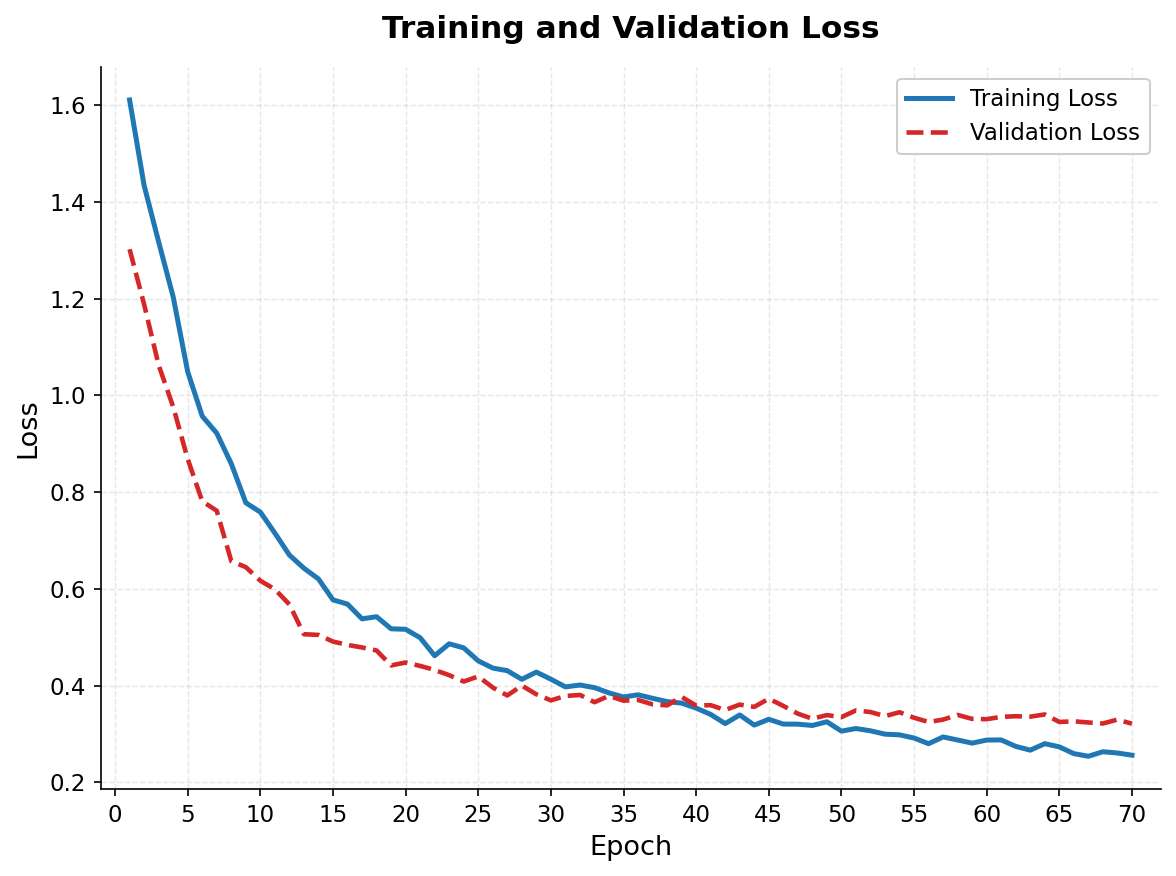

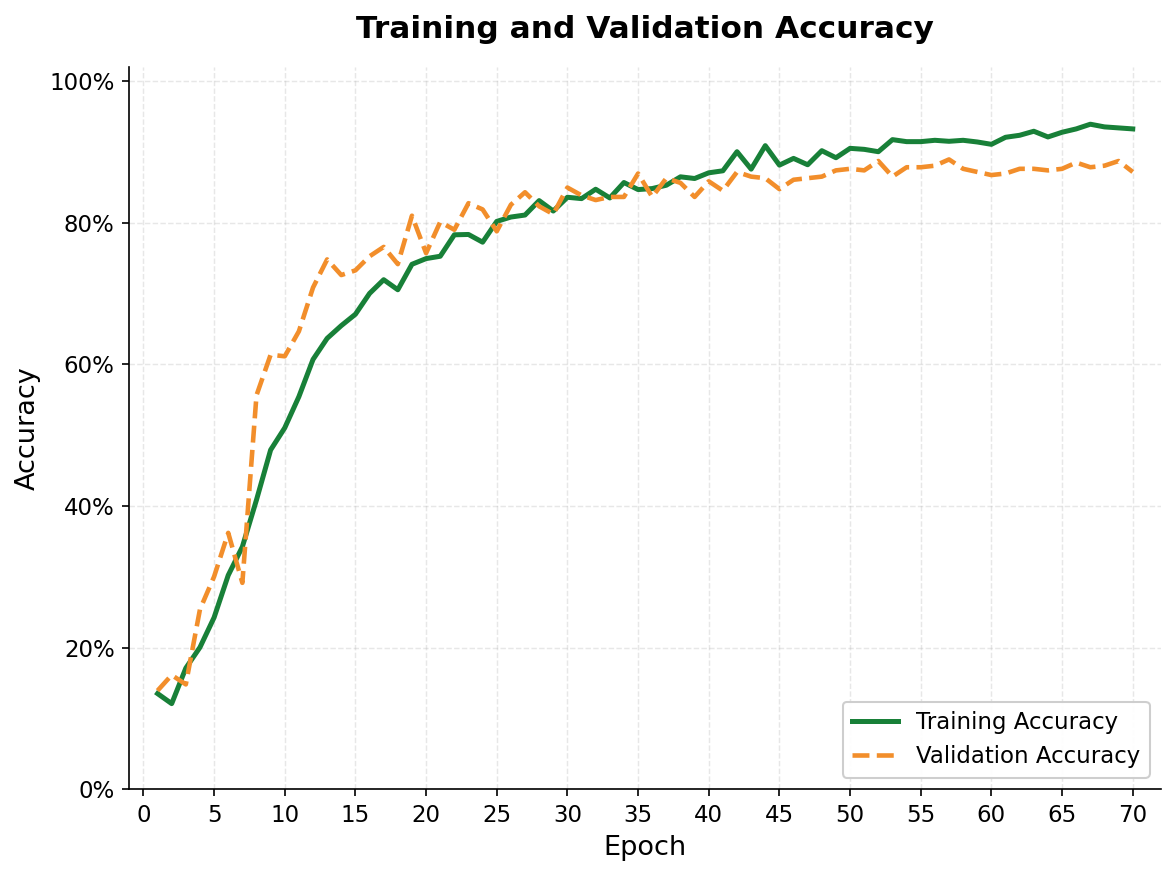

Best validation accuracy: 0.8896 at epoch 57
Best validation macro-F1: 0.8804 at epoch 57
Minimum validation loss:  0.3214 at epoch 70


In [11]:
# Paper reference: Ajay et al., "BoneVisionNet...", CMIG 2026 -- Figs. 8-28 each
# show ONE clean plot per metric: bold title, plain "Epoch"/"Loss"/"Accuracy"
# axis labels, light grid, no clutter. Loss and Accuracy are split into two
# SEPARATE figures (not one row of subplots) so each is a clean, standalone
# deliverable image.

hist = pd.read_csv(os.path.join(CKPT_DIR, "training_history.csv")).sort_values("epoch").reset_index(drop=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

epoch_min, epoch_max = hist["epoch"].min(), hist["epoch"].max()
margin = max(2, int((epoch_max - epoch_min) * 0.025))
xlim = (epoch_min - margin, epoch_max + margin)

fig, ax = plt.subplots(figsize=(8, 6), dpi=150)
fig.patch.set_facecolor("white")
ax.plot(hist["epoch"], hist["train_loss"], color="#1f77b4", linewidth=2.4, label="Training Loss")
ax.plot(hist["epoch"], hist["val_loss"], color="#d62728", linewidth=2.2, linestyle="--", label="Validation Loss")
ax.set_xlim(*xlim)
ax.set_title("Training and Validation Loss", fontweight="bold", pad=14)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.3)
ax.legend(loc="upper right", frameon=True, framealpha=0.95)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(CKPT_DIR, "fig_training_validation_loss.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

fig, ax = plt.subplots(figsize=(8, 6), dpi=150)
fig.patch.set_facecolor("white")
ax.plot(hist["epoch"], hist["train_acc"], color="#188038", linewidth=2.4, label="Training Accuracy")
ax.plot(hist["epoch"], hist["val_acc"], color="#f28e2b", linewidth=2.2, linestyle="--", label="Validation Accuracy")
ax.set_xlim(*xlim)
ax.set_ylim(0.0, 1.02)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_title("Training and Validation Accuracy", fontweight="bold", pad=14)
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.3)
ax.legend(loc="lower right", frameon=True, framealpha=0.95)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(CKPT_DIR, "fig_training_validation_accuracy.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Best validation accuracy: {hist['val_acc'].max():.4f} at epoch {int(hist.loc[hist['val_acc'].idxmax(), 'epoch'])}")
print(f"Best validation macro-F1: {hist['val_f1'].max():.4f} at epoch {int(hist.loc[hist['val_f1'].idxmax(), 'epoch'])}")
print(f"Minimum validation loss:  {hist['val_loss'].min():.4f} at epoch {int(hist.loc[hist['val_loss'].idxmin(), 'epoch'])}")

## 9. Final Test Inference — Single Source of Truth

In [12]:
# Everything from here on (confusion matrix, ROC, PR, class-wise table, XAI)
# reads from THESE three arrays only, so numbers never disagree between plots.

from sklearn.metrics import precision_score, recall_score

CLASS_COLORS = {
    cls: color for cls, color in zip(
        CLASSES,
        ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860", "#DA8BC3"][:NUM_CLASSES]
    )
}

model.load_state_dict(torch.load(os.path.join(CKPT_DIR, "best_model_final.pth"), map_location=DEVICE))
model.eval()

test_labels_all, test_probs_all = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        with autocast(DEVICE.type, enabled=(DEVICE.type == "cuda")):
            logits = model(images)
        probs = F.softmax(logits.float(), dim=1)
        with autocast(DEVICE.type, enabled=(DEVICE.type == "cuda")):
            flip_h = F.softmax(model(torch.flip(images, dims=[3])).float(), dim=1)
            flip_v = F.softmax(model(torch.flip(images, dims=[2])).float(), dim=1)
        probs = (probs + flip_h + flip_v) / 3.0
        test_probs_all.append(probs.cpu().numpy())
        test_labels_all.append(labels.numpy())

test_probs_all = np.concatenate(test_probs_all, axis=0)
test_labels_all = np.concatenate(test_labels_all, axis=0)
test_preds_all = test_probs_all.argmax(axis=1)

test_acc = accuracy_score(test_labels_all, test_preds_all)
test_f1_macro = f1_score(test_labels_all, test_preds_all, average="macro")
print(f"Test Accuracy   : {test_acc * 100:.2f}%")
print(f"Test Macro-F1   : {test_f1_macro * 100:.2f}%")
print()
print(classification_report(test_labels_all, test_preds_all, target_names=CLASSES, digits=4))

Test Accuracy   : 92.73%
Test Macro-F1   : 90.42%

              precision    recall  f1-score   support

    Bacteria     0.9770    0.9884    0.9827        86
       Fungi     0.8898    0.9375    0.9130       112
     Healthy     0.7941    0.9000    0.8438        30
    Nematode     0.8000    0.8000    0.8000        10
        Pest     0.9524    0.8791    0.9143        91
Phytophthora     0.9756    0.8696    0.9195        46
       Virus     0.9500    0.9620    0.9560        79

    accuracy                         0.9273       454
   macro avg     0.9056    0.9052    0.9042       454
weighted avg     0.9297    0.9273    0.9275       454



## 10. Confusion Matrix

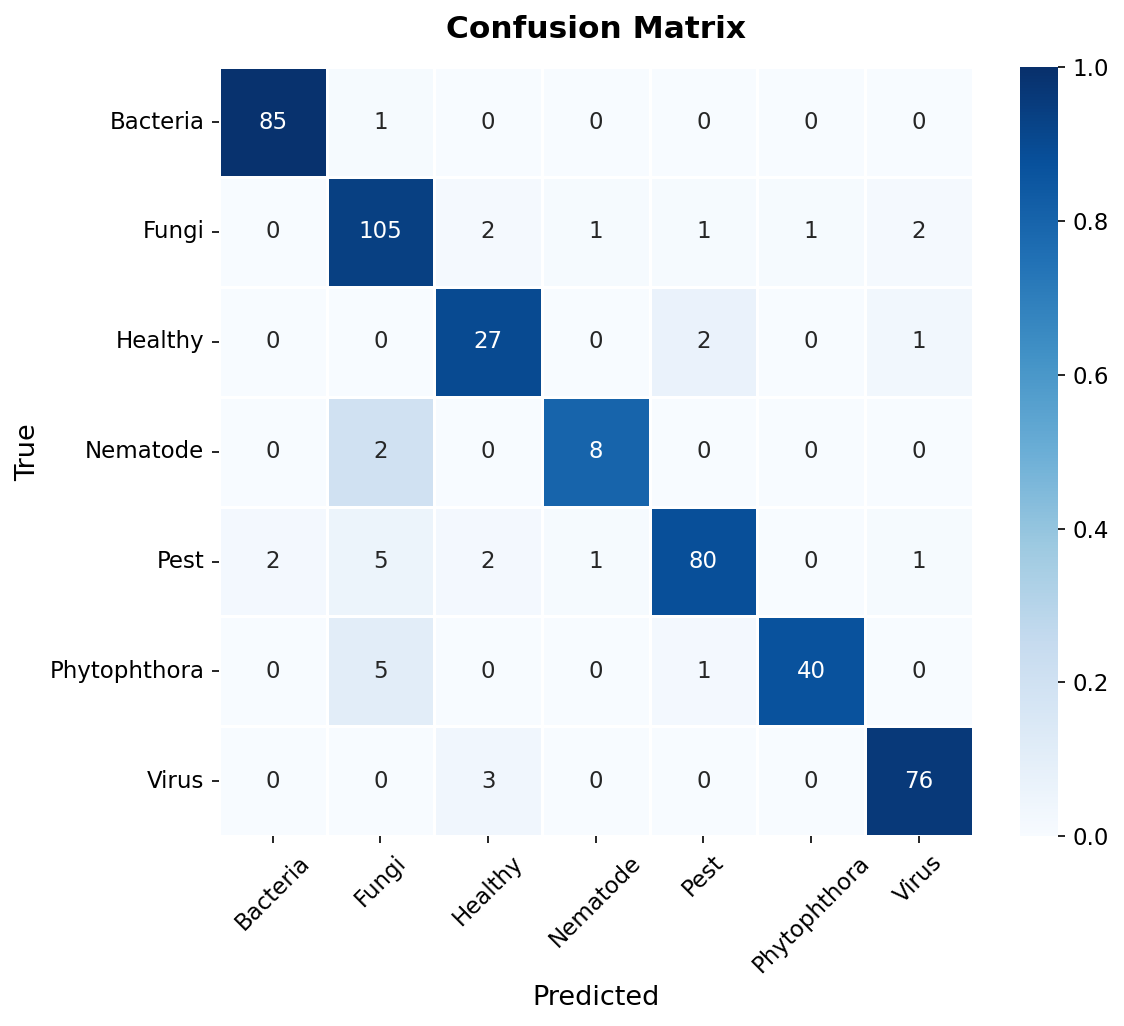

In [13]:
# Paper style: Fig. 26 -- single heatmap, bold title "Confusion Matrix",
# "Predicted" / "True" axis labels, no second panel cluttering the figure.

cm = confusion_matrix(test_labels_all, test_preds_all)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(8, 7), dpi=150)
fig.patch.set_facecolor("white")
sns.heatmap(
    cm_norm, annot=cm, fmt="d", cmap="Blues",
    xticklabels=CLASSES, yticklabels=CLASSES, cbar=True,
    vmin=0, vmax=1, ax=ax, annot_kws={"size": 11}, linewidths=0.5, linecolor="white",
)
ax.set_title("Confusion Matrix", fontweight="bold", pad=14)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
fig.savefig(os.path.join(CKPT_DIR, "fig_confusion_matrix.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 11. ROC Curve

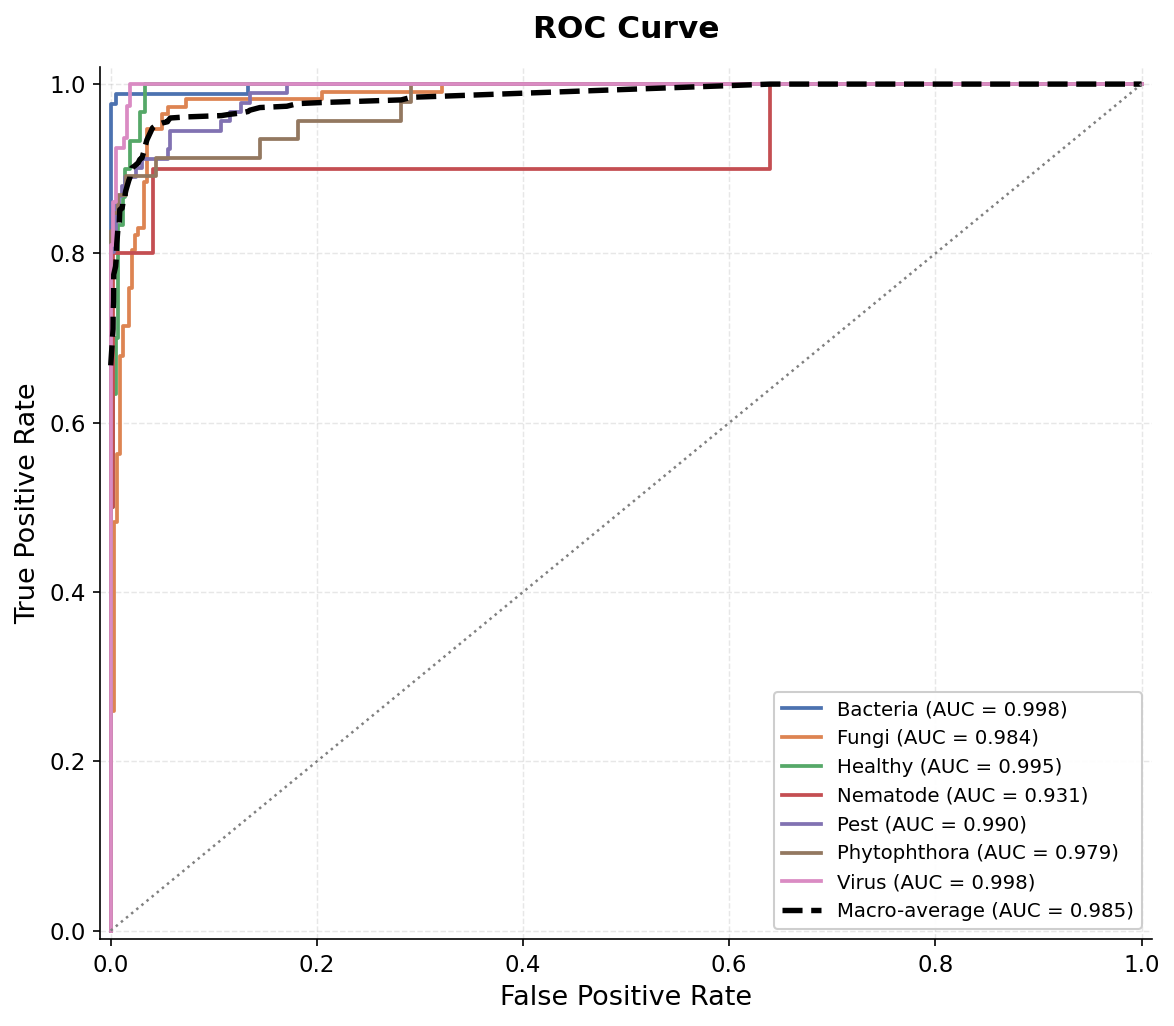

In [14]:
# Paper style: Fig. 9/12/15/... -- one figure, one curve per class (micro/macro
# averages included), bold title "ROC Curve", "False Positive Rate" /
# "True Positive Rate" axis labels, diagonal reference line.

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_true_bin = label_binarize(test_labels_all, classes=list(range(NUM_CLASSES)))

fpr, tpr, roc_auc = {}, {}, {}
for i in range(NUM_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], test_probs_all[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), test_probs_all.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

all_fpr = np.unique(np.concatenate([fpr[i] for i in range(NUM_CLASSES)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(NUM_CLASSES):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= NUM_CLASSES
fpr["macro"], tpr["macro"] = all_fpr, mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

fig, ax = plt.subplots(figsize=(8, 7), dpi=150)
fig.patch.set_facecolor("white")
for i, cls in enumerate(CLASSES):
    ax.plot(fpr[i], tpr[i], color=CLASS_COLORS[cls], linewidth=1.8,
            label=f"{cls} (AUC = {roc_auc[i]:.3f})")
ax.plot(fpr["macro"], tpr["macro"], color="black", linewidth=2.6, linestyle="--",
        label=f"Macro-average (AUC = {roc_auc['macro']:.3f})")
ax.plot([0, 1], [0, 1], color="grey", linewidth=1.2, linestyle=":")
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.02)
ax.set_title("ROC Curve", fontweight="bold", pad=14)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.3)
ax.legend(loc="lower right", frameon=True, framealpha=0.95, fontsize=9.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(CKPT_DIR, "fig_roc_curve.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 12. Precision-Recall Curve

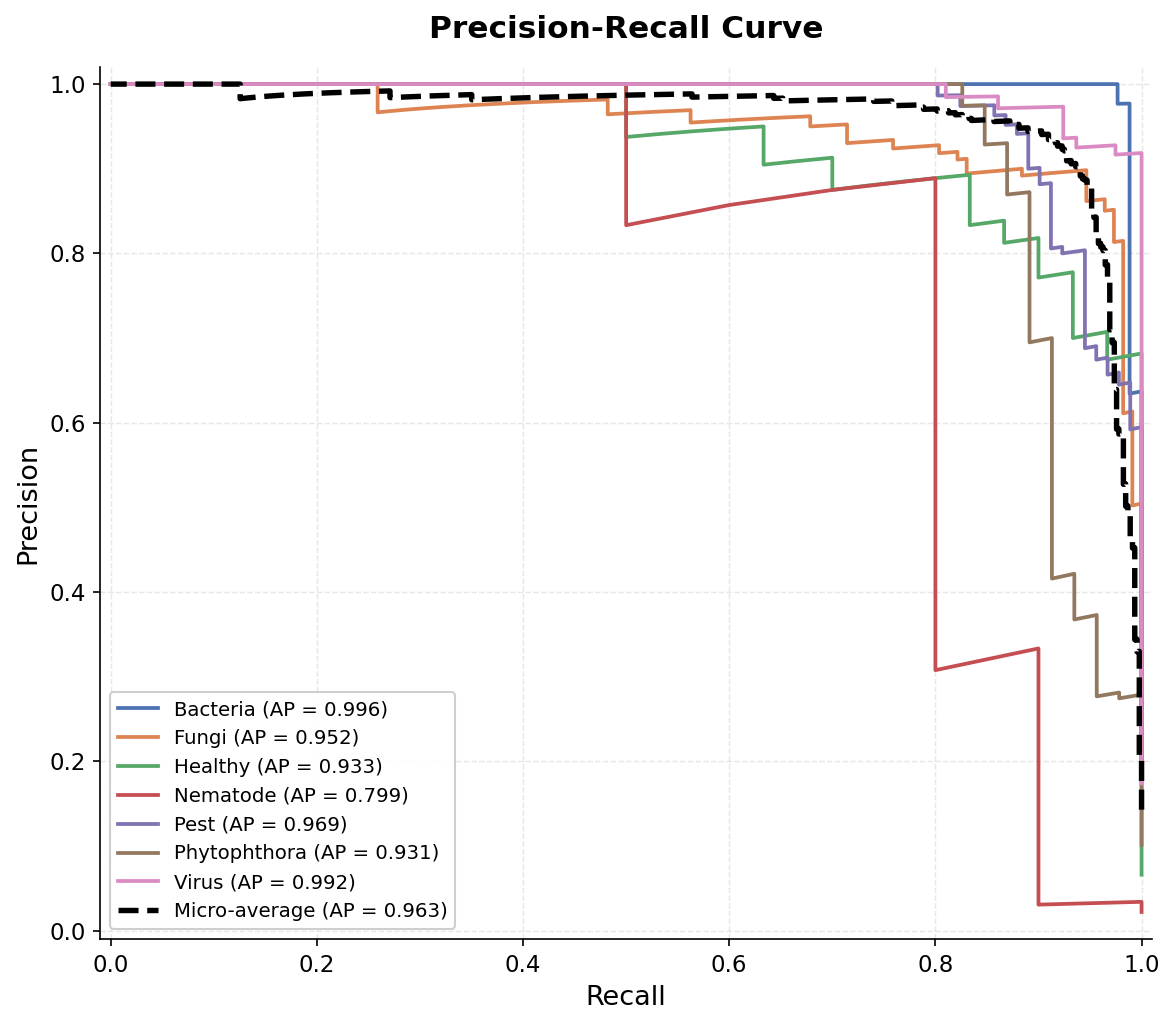

In [15]:
# Paper style: Fig. 10/13/16/... -- one figure, one curve per class,
# bold title "Precision-Recall Curve", plain "Recall" / "Precision" labels.

from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, ap = {}, {}, {}
for i in range(NUM_CLASSES):
    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], test_probs_all[:, i])
    ap[i] = average_precision_score(y_true_bin[:, i], test_probs_all[:, i])

precision["micro"], recall["micro"], _ = precision_recall_curve(y_true_bin.ravel(), test_probs_all.ravel())
ap["micro"] = average_precision_score(y_true_bin, test_probs_all, average="micro")

fig, ax = plt.subplots(figsize=(8, 7), dpi=150)
fig.patch.set_facecolor("white")
for i, cls in enumerate(CLASSES):
    ax.plot(recall[i], precision[i], color=CLASS_COLORS[cls], linewidth=1.8,
            label=f"{cls} (AP = {ap[i]:.3f})")
ax.plot(recall["micro"], precision["micro"], color="black", linewidth=2.6, linestyle="--",
        label=f"Micro-average (AP = {ap['micro']:.3f})")
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.02)
ax.set_title("Precision-Recall Curve", fontweight="bold", pad=14)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.3)
ax.legend(loc="lower left", frameon=True, framealpha=0.95, fontsize=9.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(CKPT_DIR, "fig_precision_recall_curve.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 13. Class-Wise Performance Metrics — Table (BoneVisionNet Table 9 style)

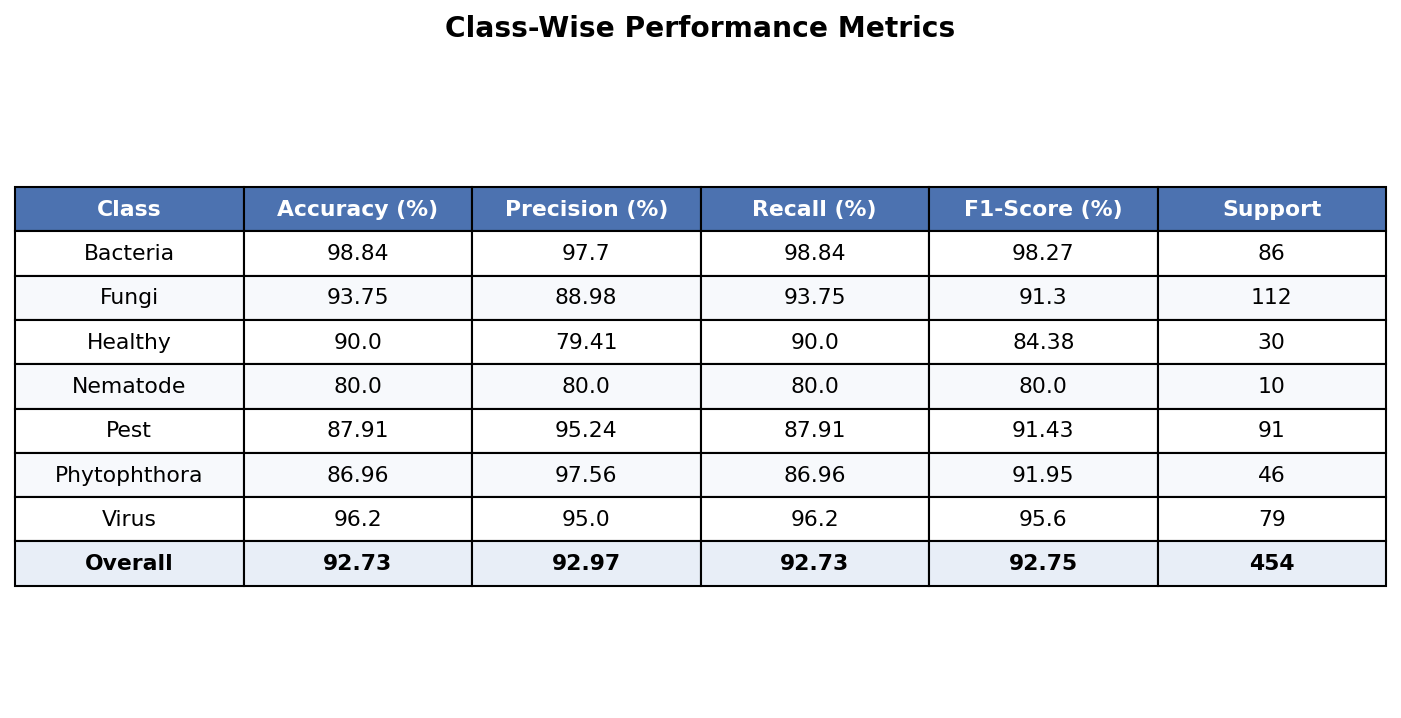

,Class,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Support
0,Bacteria,98.84,97.70,98.84,98.27,86
1,Fungi,93.75,88.98,93.75,91.30,112
2,Healthy,90.00,79.41,90.00,84.38,30
3,Nematode,80.00,80.00,80.00,80.00,10
4,Pest,87.91,95.24,87.91,91.43,91
5,Phytophthora,86.96,97.56,86.96,91.95,46
6,Virus,96.20,95.00,96.20,95.60,79
7,Overall,92.73,92.97,92.73,92.75,454


In [16]:
# Paper style: Table 9 -- Class | Accuracy (%) | Precision (%) | Recall (%) | F1-Score (%)
# with a final "Overall" row. Rendered as a real pandas DataFrame (a clean
# "Excel sheet"-style table you can .to_csv() or screenshot directly), plus a
# matplotlib table image for embedding in slides/reports.

per_class_acc = []
for i in range(NUM_CLASSES):
    mask = test_labels_all == i
    per_class_acc.append(accuracy_score(test_labels_all[mask], test_preds_all[mask]) if mask.sum() > 0 else np.nan)

per_class_precision = precision_score(test_labels_all, test_preds_all, average=None, zero_division=0)
per_class_recall = recall_score(test_labels_all, test_preds_all, average=None, zero_division=0)
per_class_f1 = f1_score(test_labels_all, test_preds_all, average=None, zero_division=0)
per_class_support = [int(np.sum(test_labels_all == i)) for i in range(NUM_CLASSES)]

class_table = pd.DataFrame({
    "Class": CLASSES,
    "Accuracy (%)": np.round(np.array(per_class_acc) * 100, 2),
    "Precision (%)": np.round(per_class_precision * 100, 2),
    "Recall (%)": np.round(per_class_recall * 100, 2),
    "F1-Score (%)": np.round(per_class_f1 * 100, 2),
    "Support": per_class_support,
})

overall_row = pd.DataFrame([{
    "Class": "Overall",
    "Accuracy (%)": round(test_acc * 100, 2),
    "Precision (%)": round(precision_score(test_labels_all, test_preds_all, average="weighted", zero_division=0) * 100, 2),
    "Recall (%)": round(recall_score(test_labels_all, test_preds_all, average="weighted", zero_division=0) * 100, 2),
    "F1-Score (%)": round(f1_score(test_labels_all, test_preds_all, average="weighted", zero_division=0) * 100, 2),
    "Support": int(len(test_labels_all)),
}])

class_table = pd.concat([class_table, overall_row], ignore_index=True)
class_table.to_csv(os.path.join(CKPT_DIR, "class_wise_metrics.csv"), index=False)

fig, ax = plt.subplots(figsize=(9.5, 0.55 * (len(class_table) + 1)), dpi=150)
fig.patch.set_facecolor("white")
ax.axis("off")
tbl = ax.table(
    cellText=class_table.values,
    colLabels=class_table.columns,
    cellLoc="center",
    loc="center",
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(10.5)
tbl.scale(1, 1.6)
for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_text_props(fontweight="bold", color="white")
        cell.set_facecolor("#4C72B0")
    elif class_table.iloc[row - 1]["Class"] == "Overall":
        cell.set_facecolor("#E8EEF7")
        cell.set_text_props(fontweight="bold")
    else:
        cell.set_facecolor("white" if row % 2 else "#F7F9FC")
ax.set_title("Class-Wise Performance Metrics", fontweight="bold", pad=16, fontsize=13.5)
fig.tight_layout()
fig.savefig(os.path.join(CKPT_DIR, "class_wise_metrics_table.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

class_table

## 14. Explainable AI (XAI) — Grad-CAM, LIME, SHAP (BoneVisionNet Table 11/12 style)

In [17]:
# # Follows Ajay et al., "BoneVisionNet...", CMIG 2026, Section 3.2.2 / Table 11-12:
# #   - Grad-CAM  : gradient-weighted class activation on the final conv block
# #   - LIME      : super-pixel perturbation on the classifier's softmax output
# #   - SHAP      : Deep/Partition SHAP pixel-level attribution with a blur masker
# #
# # One representative, correctly-classified, high-confidence test image is
# # picked per class, exactly as in the paper's XAI tables.

# get_ipython().system("pip install -q grad-cam lime shap opencv-python-headless")

# import cv2
# import shap
# from lime import lime_image
# from pytorch_grad_cam import GradCAM
# from pytorch_grad_cam.utils.image import show_cam_on_image
# from skimage.segmentation import mark_boundaries

# XAI_DIR = os.path.join(CKPT_DIR, "xai")
# os.makedirs(XAI_DIR, exist_ok=True)

# model.load_state_dict(torch.load(os.path.join(CKPT_DIR, "best_model_final.pth"), map_location=DEVICE))
# model.eval()

# class MainHeadWrapper(nn.Module):
#     """Exposes only the main classification logits, so Grad-CAM / LIME / SHAP
#     see a plain single-output classifier."""
#     def __init__(self, base_model):
#         super().__init__()
#         self.base_model = base_model

#     def forward(self, x):
#         return self.base_model(x, return_aux=False, return_embedding=False)

# wrapped_model = MainHeadWrapper(model).to(DEVICE).eval()


# def load_raw_image(path, size=IMG_SIZE):
#     image = Image.open(path).convert("RGB").resize((size, size))
#     return np.array(image).astype(np.float32) / 255.0


# def preprocess_for_model(rgb_float_image):
#     tensor = torch.tensor(rgb_float_image).permute(2, 0, 1).float()
#     mean = torch.tensor(MEAN).view(3, 1, 1)
#     std = torch.tensor(STD).view(3, 1, 1)
#     tensor = (tensor - mean) / std
#     return tensor.unsqueeze(0)


# # ---- pick one correctly-classified, high-confidence sample per class ----
# sample_rows = {}
# for i, cls in enumerate(CLASSES):
#     class_test_df = test_df[test_df["label"] == i].reset_index(drop=True)
#     best_row, best_conf = None, -1.0
#     for _, row in class_test_df.iterrows():
#         rgb = load_raw_image(row["path"])
#         input_tensor = preprocess_for_model(rgb).to(DEVICE)
#         with torch.no_grad(), autocast(DEVICE.type, enabled=(DEVICE.type == "cuda")):
#             probs = F.softmax(wrapped_model(input_tensor).float(), dim=1)[0]
#         pred = probs.argmax().item()
#         conf = probs[i].item()
#         if pred == i and conf > best_conf:
#             best_conf, best_row = conf, row
#     if best_row is None:
#         best_row = class_test_df.iloc[0]
#     sample_rows[cls] = best_row

# print("Selected one representative test image per class:")
# for cls, row in sample_rows.items():
#     print(f"  {cls:12s} - {os.path.basename(row['path'])}")

# ============================================================
# REPLACES the old "pick one correctly-classified, high-confidence
# sample per class" cell inside Section 14 of your notebook.
# Everything else in Section 14 (Grad-CAM 14.1, LIME 14.2, SHAP 14.3)
# stays EXACTLY the same -- they all just read from `sample_rows`.
# ============================================================

# ---- Updated sample-selection: avoid images dominated by hand/skin regions ----
# Rationale: a plain "highest confidence" pick can land on a photo where a hand is
# holding the leaf, and Grad-CAM/LIME then partially light up the hand instead of
# the disease lesion. We add a cheap skin-tone heuristic (YCbCr skin mask) and use
# it to PENALIZE candidates with a large hand/skin area, and additionally prefer
# images where the diseased/leaf region is large and centred in the frame.

import cv2

def skin_fraction(rgb_float_image):
    """Fraction of pixels that look like human skin, using a standard YCbCr
    skin-color range. rgb_float_image is HxWx3 in [0, 1]."""
    rgb_uint8 = (rgb_float_image * 255).astype(np.uint8)
    ycbcr = cv2.cvtColor(rgb_uint8, cv2.COLOR_RGB2YCrCb)
    y, cr, cb = ycbcr[..., 0], ycbcr[..., 1], ycbcr[..., 2]
    skin_mask = (cr >= 135) & (cr <= 180) & (cb >= 85) & (cb <= 135) & (y >= 60)
    return skin_mask.mean()


def leaf_fraction(rgb_float_image):
    """Rough fraction of pixels that are plant-leaf-colored (green/brown/yellow
    lesion tones) using HSV thresholds -- used to prefer leaf-filling images."""
    rgb_uint8 = (rgb_float_image * 255).astype(np.uint8)
    hsv = cv2.cvtColor(rgb_uint8, cv2.COLOR_RGB2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    leafy = (s > 40) & (v > 30) & (~((h < 10) | (h > 170)))  # excludes strong reds (skin/blood tones)
    return leafy.mean()


# ---- Rank several good candidates per class, then pick the one with the
# largest leaf area and smallest skin/hand area, among correctly-classified,
# reasonably-confident predictions ----
TOP_K_CANDIDATES = 8       # how many correctly-classified images to shortlist before ranking
MIN_CONFIDENCE = 0.55      # ignore low-confidence correct predictions
MAX_SKIN_FRACTION = 0.12   # hard cap -- discard candidates with more hand/skin than this

sample_rows = {}
candidate_previews = {}  # kept for optional manual inspection below

for i, cls in enumerate(CLASSES):
    class_test_df = test_df[test_df["label"] == i].reset_index(drop=True)
    scored_candidates = []

    for _, row in class_test_df.iterrows():
        rgb = load_raw_image(row["path"])
        input_tensor = preprocess_for_model(rgb).to(DEVICE)
        with torch.no_grad(), autocast(DEVICE.type, enabled=(DEVICE.type == "cuda")):
            probs = F.softmax(wrapped_model(input_tensor).float(), dim=1)[0]
        pred = probs.argmax().item()
        conf = probs[i].item()
        if pred != i or conf < MIN_CONFIDENCE:
            continue

        skin_frac = skin_fraction(rgb)
        leaf_frac = leaf_fraction(rgb)
        if skin_frac > MAX_SKIN_FRACTION:
            continue  # too much hand in frame -- skip outright

        # Higher score = more leaf coverage, less skin, higher confidence
        score = leaf_frac - 2.0 * skin_frac + 0.15 * conf
        scored_candidates.append((score, conf, skin_frac, leaf_frac, row))

    scored_candidates.sort(key=lambda item: item[0], reverse=True)
    candidate_previews[cls] = scored_candidates[:TOP_K_CANDIDATES]

    if scored_candidates:
        best = scored_candidates[0]
        sample_rows[cls] = best[4]
    else:
        # fallback: no candidate passed the skin filter -- use the least-skin one
        fallback_pool = []
        for _, row in class_test_df.iterrows():
            rgb = load_raw_image(row["path"])
            fallback_pool.append((skin_fraction(rgb), row))
        fallback_pool.sort(key=lambda item: item[0])
        sample_rows[cls] = fallback_pool[0][1]

print("Selected one hand-free, leaf-focused test image per class:")
for cls, row in sample_rows.items():
    print(f"  {cls:12s} - {os.path.basename(row['path'])}")


# ============================================================
# OPTIONAL: preview the top-ranked candidates per class before committing.
# Run this to SEE the shortlist and manually override sample_rows[cls] with
# a different path if the automatic picks still aren't ideal for a class.
# ============================================================

fig, axes = plt.subplots(NUM_CLASSES, TOP_K_CANDIDATES, figsize=(2.0 * TOP_K_CANDIDATES, 2.0 * NUM_CLASSES), dpi=110)
fig.patch.set_facecolor("white")
for row_idx, cls in enumerate(CLASSES):
    candidates = candidate_previews[cls]
    for col_idx in range(TOP_K_CANDIDATES):
        ax = axes[row_idx, col_idx]
        if col_idx < len(candidates):
            score, conf, skin_frac, leaf_frac, row = candidates[col_idx]
            rgb = load_raw_image(row["path"])
            ax.imshow(rgb)
            ax.set_title(f"skin={skin_frac:.2f}\nleaf={leaf_frac:.2f}", fontsize=7)
        ax.axis("off")
    axes[row_idx, 0].set_ylabel(cls, fontsize=10, fontweight="bold", rotation=0, labelpad=45)
    axes[row_idx, 0].axis("on"); axes[row_idx, 0].set_xticks([]); axes[row_idx, 0].set_yticks([])
fig.suptitle("Candidate Shortlist per Class (ranked by leaf coverage, low skin/hand)", fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

# To manually override a pick, e.g. use the 3rd-ranked "Fungi" candidate instead:
#   sample_rows["Fungi"] = candidate_previews["Fungi"][2][4]
#
# After overriding, just re-run the existing Grad-CAM (14.1) and LIME (14.2)
# cells -- they already read from `sample_rows` and need no other changes.

NameError: name 'load_raw_image' is not defined

### 14.1 Grad-CAM

In [ ]:
# Grad-CAM on model.apa (final custom block, fed by the full ResNet's output
# feature maps), matching the paper's approach of probing the final
# convolutional layer before the pooling heads.

target_layer = model.apa
cam_extractor = GradCAM(model=wrapped_model, target_layers=[target_layer])

gradcam_maps = {}
for cls, row in sample_rows.items():
    rgb = load_raw_image(row["path"])
    input_tensor = preprocess_for_model(rgb).to(DEVICE)
    grayscale_cam = cam_extractor(input_tensor=input_tensor, targets=None)[0]
    overlay = show_cam_on_image(rgb, grayscale_cam, use_rgb=True, colormap=cv2.COLORMAP_JET)
    gradcam_maps[cls] = (rgb, grayscale_cam, overlay)

fig, axes = plt.subplots(3, NUM_CLASSES, figsize=(3.0 * NUM_CLASSES, 8.6), dpi=150)
fig.patch.set_facecolor("white")
for col, cls in enumerate(CLASSES):
    rgb, gray_cam, overlay = gradcam_maps[cls]
    axes[0, col].imshow(rgb)
    axes[0, col].set_title(cls, fontweight="bold", fontsize=11)
    axes[1, col].imshow(gray_cam, cmap="jet")
    axes[2, col].imshow(overlay)
    for r in range(3):
        axes[r, col].axis("off")
axes[0, 0].set_ylabel("Original", fontsize=10.5); axes[0, 0].axis("on"); axes[0, 0].set_xticks([]); axes[0, 0].set_yticks([])
axes[1, 0].set_ylabel("Grad-CAM Heatmap", fontsize=10.5); axes[1, 0].axis("on"); axes[1, 0].set_xticks([]); axes[1, 0].set_yticks([])
axes[2, 0].set_ylabel("Overlay", fontsize=10.5); axes[2, 0].axis("on"); axes[2, 0].set_xticks([]); axes[2, 0].set_yticks([])
fig.suptitle("Grad-CAM Explanations — One Sample per Class", fontweight="bold", fontsize=14.5, y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(XAI_DIR, "gradcam_all_classes.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

### 14.2 LIME

In [ ]:
# LIME super-pixel perturbation on the softmax output, exactly as in the paper.

explainer = lime_image.LimeImageExplainer()

def lime_predict_fn(images_batch):
    tensors = []
    for image in images_batch:
        image_float = image.astype(np.float32)
        if image_float.max() > 1.5:
            image_float = image_float / 255.0
        tensors.append(preprocess_for_model(image_float))
    batch_tensor = torch.cat(tensors, dim=0).to(DEVICE)
    with torch.no_grad(), autocast(DEVICE.type, enabled=(DEVICE.type == "cuda")):
        probs = F.softmax(wrapped_model(batch_tensor).float(), dim=1)
    return probs.cpu().numpy()

lime_maps = {}
for cls, row in sample_rows.items():
    rgb = load_raw_image(row["path"])
    target_idx = CLASS_TO_IDX[cls]
    explanation = explainer.explain_instance(
        rgb, lime_predict_fn, top_labels=NUM_CLASSES, hide_color=0, num_samples=800
    )
    temp, mask = explanation.get_image_and_mask(
        target_idx, positive_only=True, num_features=8, hide_rest=False
    )
    boundary_image = mark_boundaries(temp, mask, color=(1, 0, 0), mode="thick")
    lime_maps[cls] = (rgb, boundary_image)
    # lime_maps[cls] = (rgb, mark_boundaries(temp, mask))


fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(3.0 * NUM_CLASSES, 6.2), dpi=150)
fig.patch.set_facecolor("white")
for col, cls in enumerate(CLASSES):
    rgb, boundary_image = lime_maps[cls]
    axes[0, col].imshow(rgb)
    axes[0, col].set_title(cls, fontweight="bold", fontsize=11)
    axes[1, col].imshow(boundary_image)
    axes[0, col].axis("off"); axes[1, col].axis("off")
axes[0, 0].axis("on"); axes[0, 0].set_xticks([]); axes[0, 0].set_yticks([]); axes[0, 0].set_ylabel("Original", fontsize=10.5)
axes[1, 0].axis("on"); axes[1, 0].set_xticks([]); axes[1, 0].set_yticks([]); axes[1, 0].set_ylabel("LIME Super-Pixels", fontsize=10.5)
fig.suptitle("LIME Explanations — One Sample per Class", fontweight="bold", fontsize=14.5, y=1.01)
fig.tight_layout()
fig.savefig(os.path.join(XAI_DIR, "lime_all_classes.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

### 14.3 SHAP (fixed)

In [ ]:
# SHAP via the Partition explainer with a blur masker, matching the paper's
# "Deep SHAP ... blur masker ... batch size 32" setup.
#
# ROOT CAUSE OF THE ORIGINAL ERROR
# ---------------------------------
# shap.Explainer(...) on an image model returns `shap_values.values` with
# shape (H, W, C, num_outputs) -- e.g. (512, 512, 3, 1) when only ONE class's
# attribution was requested. Passing that 4-D array straight to `imshow`
# fails because imshow only accepts (H, W), (H, W, 3) or (H, W, 4).
# FIX: always index/squeeze the trailing "num_outputs" axis down to a plain
# (H, W) attribution map (summed over channels) before plotting.

def to_2d_attribution(attribution):
    """Robustly collapse a SHAP attribution array of any of the shapes
    SHAP can return -- (H,W), (H,W,C), (H,W,C,1), (H,W,C,K) -- into a
    single (H, W) map suitable for imshow with a diverging colormap."""
    arr = np.asarray(attribution)
    if arr.ndim == 4:
        arr = arr[..., 0] if arr.shape[-1] == 1 else arr[..., 0]
    if arr.ndim == 3:
        arr = arr.sum(axis=-1)
    return arr  # now guaranteed (H, W)


def shap_predict_fn(images_batch):
    tensors = []
    for image in images_batch:
        image_float = image.astype(np.float32)
        if image_float.max() > 1.5:
            image_float = image_float / 255.0
        tensors.append(preprocess_for_model(image_float))
    batch_tensor = torch.cat(tensors, dim=0).to(DEVICE)
    with torch.no_grad(), autocast(DEVICE.type, enabled=(DEVICE.type == "cuda")):
        probs = F.softmax(wrapped_model(batch_tensor).float(), dim=1)
    return probs.cpu().numpy()


masker = shap.maskers.Image("blur(32,32)", (IMG_SIZE, IMG_SIZE, 3))
shap_explainer = shap.Explainer(shap_predict_fn, masker, output_names=CLASSES)

shap_maps = {}
for cls, row in sample_rows.items():
    rgb = load_raw_image(row["path"])
    target_idx = CLASS_TO_IDX[cls]
    input_for_shap = np.expand_dims(rgb, axis=0)
    shap_values = shap_explainer(
        input_for_shap,
        max_evals=500,
        batch_size=32,
        outputs=[target_idx],
    )
    attribution = to_2d_attribution(shap_values.values[0])
    shap_maps[cls] = (rgb, attribution)

vmax = max(np.abs(attr).max() for _, attr in shap_maps.values())
vmax = vmax if vmax > 0 else 1.0

fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(3.0 * NUM_CLASSES, 6.2), dpi=150)
fig.patch.set_facecolor("white")
for col, cls in enumerate(CLASSES):
    rgb, attribution = shap_maps[cls]
    axes[0, col].imshow(rgb)
    axes[0, col].set_title(cls, fontweight="bold", fontsize=11)
    axes[1, col].imshow(rgb)
    im = axes[1, col].imshow(attribution, cmap="bwr", alpha=0.55, vmin=-vmax, vmax=vmax)
    axes[0, col].axis("off"); axes[1, col].axis("off")
axes[0, 0].axis("on"); axes[0, 0].set_xticks([]); axes[0, 0].set_yticks([]); axes[0, 0].set_ylabel("Original", fontsize=10.5)
axes[1, 0].axis("on"); axes[1, 0].set_xticks([]); axes[1, 0].set_yticks([]); axes[1, 0].set_ylabel("SHAP Attribution", fontsize=10.5)
cbar = fig.colorbar(im, ax=axes[1, :].tolist(), orientation="horizontal", fraction=0.05, pad=0.06, shrink=0.6)
cbar.set_label("Positive (red) vs. negative (blue) contribution", fontsize=9.5)
fig.suptitle("SHAP Explanations — One Sample per Class", fontweight="bold", fontsize=14.5, y=1.02)
fig.savefig(os.path.join(XAI_DIR, "shap_all_classes.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 15. Summary — All Deliverables

In [ ]:
# Everything this notebook produced, in one place. Every path below is a
# saved PNG/CSV -- nothing is scattered across scroll positions anymore.

print("Curves:")
print(f"  {os.path.join(CKPT_DIR, 'fig_training_validation_loss.png')}")
print(f"  {os.path.join(CKPT_DIR, 'fig_training_validation_accuracy.png')}")
print()
print("Evaluation figures:")
print(f"  {os.path.join(CKPT_DIR, 'fig_confusion_matrix.png')}")
print(f"  {os.path.join(CKPT_DIR, 'fig_roc_curve.png')}")
print(f"  {os.path.join(CKPT_DIR, 'fig_precision_recall_curve.png')}")
print()
print("Class-wise metrics table:")
print(f"  {os.path.join(CKPT_DIR, 'class_wise_metrics.csv')}")
print(f"  {os.path.join(CKPT_DIR, 'class_wise_metrics_table.png')}")
print()
print("XAI visualisations:")
print(f"  {os.path.join(XAI_DIR, 'gradcam_all_classes.png')}")
print(f"  {os.path.join(XAI_DIR, 'lime_all_classes.png')}")
print(f"  {os.path.join(XAI_DIR, 'shap_all_classes.png')}")
print()
class_table